# Does EarlyDecision help on FineWeb?

This notebook compares EarlyDecision's spelling flag with the full annotation results in `data/fineweb`. **Every passage was sent for annotation** (`p_annotated_anyway=1.0` in the saved configuration), including those marked clean. We can therefore estimate what the gate would have skipped without treating skipped passages as clean.

The annotation model is a **comparison signal, not ground truth**. “Annotation-positive” means at least one returned correction; it does not guarantee a genuine spelling error. All metrics below describe this local sample and these model outputs. The notebook reads local files only and makes no model or network calls.

In [1]:
import itertools
import json
from collections import Counter
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from IPython.display import HTML, Markdown, display

plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)


def table(headers, rows):
    """Render readable tables without truncating cell contents."""
    head = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(
        HTML(
            f'<div style="overflow-x:auto"><table><thead><tr>{head}</tr>'
            f"</thead><tbody>{body}</tbody></table></div>"
        )
    )


def ratio(numerator, denominator):
    return numerator / denominator if denominator else float("nan")


def percent(numerator, denominator):
    return f"{numerator / denominator:.1%}" if denominator else "undefined (n=0)"


root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file() and (path / "data/fineweb").is_dir()
    ),
    None,
)
if root is None:
    raise FileNotFoundError("Run from the repository root or its notebooks directory.")
data_dir = root / "data/fineweb"
config = yaml.safe_load((data_dir / "config.yaml").read_text())
if config.get("p_annotated_anyway") != 1.0:
    raise ValueError(
        "This analysis requires complete annotation sampling (p_annotated_anyway=1.0)."
    )

rows = []
shards = sorted(data_dir.glob("part-*.jsonl"))
for shard in shards:
    for line_number, line in enumerate(shard.read_text().splitlines(), start=1):
        if not line.strip():
            continue
        row = json.loads(line)
        row["id"] = f"{shard.name}:{line_number}"
        row["flag"] = (
            row["decision"]["contains_spelling_error"]
            if row["decision"] is not None
            else None
        )
        row["confidence"] = (
            row["decision"]["confidence"] if row["decision"] is not None else None
        )
        row["positive"] = (
            bool(row["annotations"]) if row["annotations"] is not None else None
        )
        row["corrections"] = len(row["annotations"] or [])
        row["chars"] = len(row["text"])
        rows.append(row)
if not rows:
    raise ValueError(f"No passages found in {data_dir}.")

known = [row for row in rows if row["positive"] is not None]
paired = [row for row in known if row["flag"] is not None]
clean = [row for row in known if row["flag"] is False]
flagged = [row for row in known if row["flag"] is True]
positives = sum(row["positive"] for row in known)
corrections = sum(row["corrections"] for row in known)
counts = Counter((row["flag"], row["positive"]) for row in paired)
tn, fn = counts[False, False], counts[False, True]
fp, tp = counts[True, False], counts[True, True]

table(
    ["Setting", "Value"],
    [
        ("Local data", f"{len(rows)} passages in {len(shards)} shards"),
        (
            "Dataset / subset / split",
            f"{config['dataset']} / {config['subset']} / {config['split']}",
        ),
        ("EarlyDecision model", config["early_decision"]["model"]),
        ("Annotation model", config["annotation"]["model"]),
        ("p_annotated_anyway", config["p_annotated_anyway"]),
    ],
)

Setting,Value
Local data,100 passages in 10 shards
Dataset / subset / split,HuggingFaceFW/fineweb / sample-10BT / train
EarlyDecision model,typesafe/jev-1.14
Annotation model,z-ai/glm-5.3-flash:floor
p_annotated_anyway,1.0


## Coverage and overview

An empty annotation list is a usable negative result for this fully sampled run; `null` is unavailable and is excluded from annotation-based rates. A missing decision is **unknown**, not clean; the production gate always annotates it. Failure histories can include recovered retries or partial results, so we report them without automatically discarding those passages.

In [2]:
table(
    ["Measure", "Count / value"],
    [
        ("Passages", len(rows)),
        ("Flagged", f"{sum(r['flag'] is True for r in rows)} / {len(rows)}"),
        ("Marked clean", f"{sum(r['flag'] is False for r in rows)} / {len(rows)}"),
        ("Missing decisions", sum(r["flag"] is None for r in rows)),
        ("Unavailable annotation results", len(rows) - len(known)),
        (
            "Annotation-positive passages",
            f"{positives} / {len(known)} ({percent(positives, len(known))})",
        ),
        ("Individual corrections", corrections),
        (
            "Passages with annotation failure history",
            sum(bool(r["failures"]) for r in rows),
        ),
        (
            "Passages with decision failure history",
            sum(bool(r["early_decision_failures"]) for r in rows),
        ),
    ],
)

table(
    [
        "Decision group",
        "Passages",
        "Usable annotation results",
        "Annotation-positive",
        "% positive among usable",
        "Corrections",
    ],
    [
        (
            label,
            len(group),
            len(usable),
            sum(r["positive"] for r in usable),
            percent(sum(r["positive"] for r in usable), len(usable)),
            sum(r["corrections"] for r in usable),
        )
        for label, flag in [
            ("Marked clean", False),
            ("Flagged", True),
            ("Unknown", None),
        ]
        for group in [[r for r in rows if r["flag"] is flag]]
        for usable in [[r for r in group if r["positive"] is not None]]
    ],
)

table(
    ["Text length (characters)", "Minimum", "Median", "90th percentile", "Maximum"],
    [
        (
            "All passages",
            *(
                f"{value:,.0f}"
                for value in np.percentile([r["chars"] for r in rows], [0, 50, 90, 100])
            ),
        )
    ],
)

diagnostics = [r for r in rows if r["failures"] or r["early_decision_failures"]]
if diagnostics:
    table(
        ["Passage", "Annotation result", "Diagnostic history"],
        [
            (
                r["id"],
                "unavailable"
                if r["positive"] is None
                else f"{r['corrections']} corrections",
                "; ".join(
                    f"{kind}: attempt {f['attempt']}: {f['error']}"
                    for kind, failures in [
                        ("annotation", r["failures"]),
                        ("decision", r["early_decision_failures"]),
                    ]
                    for f in failures
                ),
            )
            for r in diagnostics
        ],
    )
else:
    display(Markdown("No recorded validation failure histories."))

Measure,Count / value
Passages,100
Flagged,32 / 100
Marked clean,68 / 100
Missing decisions,0
Unavailable annotation results,0
Annotation-positive passages,32 / 100 (32.0%)
Individual corrections,43
Passages with annotation failure history,3
Passages with decision failure history,0


Decision group,Passages,Usable annotation results,Annotation-positive,% positive among usable,Corrections
Marked clean,68,68,10,14.7%,10
Flagged,32,32,22,68.8%,33
Unknown,0,0,0,undefined (n=0),0


Text length (characters),Minimum,Median,90th percentile,Maximum
All passages,321,"2,094","5,476","33,891"


Passage,Annotation result,Diagnostic history
part-00000.jsonl:6,1 corrections,annotation: attempt 1: corrections.0: exact context 'Augustanawith with a fourth' is missing from passage
part-00004.jsonl:9,3 corrections,annotation: attempt 1: corrections.0: exact context 'places/situtationsitutation we need' is missing from passage; annotation: attempt 1: corrections.1: exact context 'One possiblilitypossiblility would be' is missing from passage; annotation: attempt 1: corrections.2: exact context 'would definatelydefinately start' is missing from passage
part-00005.jsonl:3,1 corrections,annotation: attempt 1: corrections.0: exact context '” said Malmborg. “We know' is missing from passage; annotation: attempt 2: corrections.0: exact context 'said Malmborg. “We know' is missing from passage


## Agreement and what the current gate would lose

The matrix includes only passages with both a usable decision and annotation result. Precision, recall, specificity, and agreement below use annotation presence as the reference label. In particular, an apparent false negative can reflect either a missed spelling error or an annotation outside the requested scope.

The production gate annotates flagged **and unknown** decisions. Its call savings use all passages; its retention rates use only available annotation results. Retaining a passage means retaining all corrections returned for it in this run.

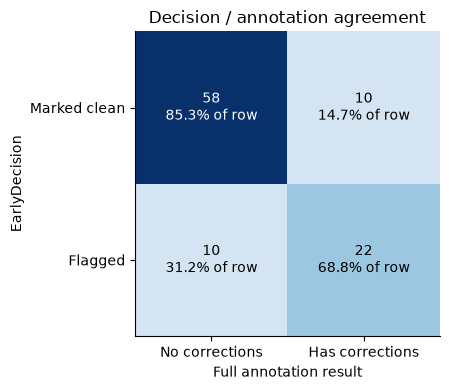

Measure,Numerator / denominator,Rate
Non-flagged passages with annotations,10 / 68,14.7%
Flagged passages with annotations (precision),22 / 32,68.8%
Flag recall among paired passages,22 / 32,68.8%
Specificity among paired passages,58 / 68,85.3%
Agreement among paired passages,80 / 100,80.0%
Annotation calls avoided by current gate,68 / 100,68.0%
Annotated passages retained by current gate,22 / 32,68.8%
Individual corrections retained by current gate,33 / 43,76.7%


In [3]:
matrix = np.array([[tn, fn], [fp, tp]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(1, int(matrix.max())))
for (i, j), value in np.ndenumerate(matrix):
    ax.text(
        j,
        i,
        f"{value}\n{percent(value, int(matrix[i].sum()))} of row",
        ha="center",
        va="center",
        color="white" if value > matrix.max() / 2 else "black",
    )
ax.set(
    xticks=[0, 1],
    xticklabels=["No corrections", "Has corrections"],
    yticks=[0, 1],
    yticklabels=["Marked clean", "Flagged"],
    xlabel="Full annotation result",
    ylabel="EarlyDecision",
    title="Decision / annotation agreement",
)
plt.tight_layout()
plt.show()


def evaluate_policy(label, should_annotate):
    selected = [r for r in rows if should_annotate(r)]
    usable = [r for r in selected if r["positive"] is not None]
    retained = sum(r["positive"] for r in usable)
    retained_corrections = sum(r["corrections"] for r in usable)
    return {
        "label": label,
        "calls": len(selected),
        "avoided": len(rows) - len(selected),
        "retained": retained,
        "retained_corrections": retained_corrections,
        "passage_recall": ratio(retained, positives),
        "correction_recall": ratio(retained_corrections, corrections),
    }


def current_gate(row):
    return row["flag"] is not False


baseline = evaluate_policy("Current gate", current_gate)
table(
    ["Measure", "Numerator / denominator", "Rate"],
    [
        (
            "Non-flagged passages with annotations",
            f"{fn} / {len(clean)}",
            percent(fn, len(clean)),
        ),
        (
            "Flagged passages with annotations (precision)",
            f"{tp} / {len(flagged)}",
            percent(tp, len(flagged)),
        ),
        (
            "Flag recall among paired passages",
            f"{tp} / {tp + fn}",
            percent(tp, tp + fn),
        ),
        (
            "Specificity among paired passages",
            f"{tn} / {tn + fp}",
            percent(tn, tn + fp),
        ),
        (
            "Agreement among paired passages",
            f"{tp + tn} / {len(paired)}",
            percent(tp + tn, len(paired)),
        ),
        (
            "Annotation calls avoided by current gate",
            f"{baseline['avoided']} / {len(rows)}",
            percent(baseline["avoided"], len(rows)),
        ),
        (
            "Annotated passages retained by current gate",
            f"{baseline['retained']} / {positives}",
            percent(baseline["retained"], positives),
        ),
        (
            "Individual corrections retained by current gate",
            f"{baseline['retained_corrections']} / {corrections}",
            percent(baseline["retained_corrections"], corrections),
        ),
    ],
)

## Confidence and passage length

The stored confidence is certainty in the **selected choice**, not a probability of spelling errors. Do not convert it to `P(error)` or interpret this as a probability calibration plot. Each confidence bin below shows the observed annotation-positive fraction, separately for clean and flagged choices; labels give sample sizes.

Length groups use characters and fixed boundaries, so they remain comparable if more shards are added. These are descriptive associations, not evidence that confidence or length causes disagreements.

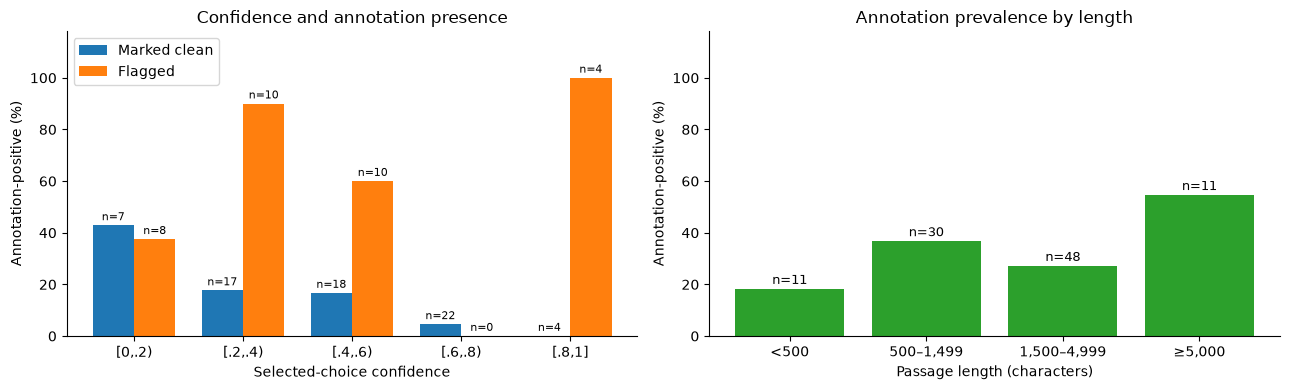

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
edges = np.linspace(0, 1, 6)
x = np.arange(len(edges) - 1)
for flag, label, offset, color in [
    (False, "Marked clean", -0.19, "tab:blue"),
    (True, "Flagged", 0.19, "tab:orange"),
]:
    groups = [
        [
            r
            for r in paired
            if r["flag"] is flag
            and lo <= r["confidence"]
            and (r["confidence"] < hi or (hi == 1 and r["confidence"] == 1))
        ]
        for lo, hi in itertools.pairwise(edges)
    ]
    values = [100 * ratio(sum(r["positive"] for r in g), len(g)) for g in groups]
    axes[0].bar(x + offset, values, width=0.38, label=label, color=color)
    for position, value, group in zip(x + offset, values, groups):
        axes[0].text(
            position,
            value + 2 if np.isfinite(value) else 2,
            f"n={len(group)}",
            ha="center",
            fontsize=8,
        )
axes[0].set(
    xticks=x,
    xticklabels=["[0,.2)", "[.2,.4)", "[.4,.6)", "[.6,.8)", "[.8,1]"],
    ylim=(0, 118),
    ylabel="Annotation-positive (%)",
    xlabel="Selected-choice confidence",
    title="Confidence and annotation presence",
)
axes[0].legend()

length_bins = [
    (0, 500, "<500"),
    (500, 1500, "500–1,499"),
    (1500, 5000, "1,500–4,999"),
    (5000, float("inf"), "≥5,000"),
]
length_groups = [
    [r for r in known if lo <= r["chars"] < hi] for lo, hi, _ in length_bins
]
values = [100 * ratio(sum(r["positive"] for r in g), len(g)) for g in length_groups]
axes[1].bar(range(len(length_bins)), values, color="tab:green")
for position, value, group in zip(range(len(length_bins)), values, length_groups):
    axes[1].text(
        position,
        value + 2 if np.isfinite(value) else 2,
        f"n={len(group)}",
        ha="center",
        fontsize=9,
    )
axes[1].set(
    xticks=range(len(length_bins)),
    xticklabels=[b[2] for b in length_bins],
    ylim=(0, 118),
    ylabel="Annotation-positive (%)",
    xlabel="Passage length (characters)",
    title="Annotation prevalence by length",
)
plt.tight_layout()
plt.show()

## Could a confidence override recover useful passages?

Compare the existing gate with “annotate flagged or unknown, **plus clean decisions with confidence strictly below the threshold**.” A threshold of `1.00` still skips clean decisions with confidence exactly `1.00`; “annotate all” is a separate baseline.

The curve evaluates every distinct policy reachable at observed clean confidence values (including equality boundaries). The table gives fixed reference thresholds. This is an exploratory in-sample tradeoff, not threshold selection on held-out data. “Calls” means passages sent for annotation, excluding retries and the extra EarlyDecision requests; no monetary or latency savings can be inferred from these counts alone.

Policy,Calls,Calls avoided,Annotated passages retained,Corrections retained
Current gate,32,68 (68.0%),22/32 (68.8%),33/43 (76.7%)
Clean confidence < 0.25,44,56 (56.0%),26/32 (81.2%),37/43 (86.0%)
Clean confidence < 0.50,62,38 (38.0%),28/32 (87.5%),39/43 (90.7%)
Clean confidence < 0.75,89,11 (11.0%),32/32 (100.0%),43/43 (100.0%)
Clean confidence < 1.00,100,0 (0.0%),32/32 (100.0%),43/43 (100.0%)
Annotate all,100,0 (0.0%),32/32 (100.0%),43/43 (100.0%)


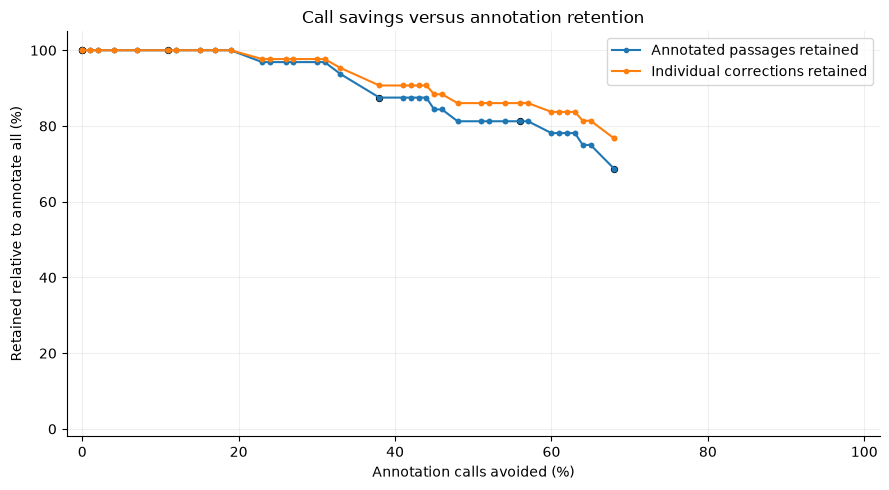

In [5]:
def threshold_gate(row, threshold):
    return current_gate(row) or row["confidence"] < threshold


def threshold_policy(threshold):
    return evaluate_policy(
        f"Clean confidence < {threshold:.2f}",
        lambda row: threshold_gate(row, threshold),
    )


annotate_all = evaluate_policy("Annotate all", lambda row: True)
reference_policies = [
    baseline,
    *(threshold_policy(t) for t in [0.25, 0.50, 0.75, 1.00]),
    annotate_all,
]
table(
    [
        "Policy",
        "Calls",
        "Calls avoided",
        "Annotated passages retained",
        "Corrections retained",
    ],
    [
        (
            p["label"],
            p["calls"],
            f"{p['avoided']} ({percent(p['avoided'], len(rows))})",
            f"{p['retained']}/{positives} ({percent(p['retained'], positives)})",
            f"{p['retained_corrections']}/{corrections} ({percent(p['retained_corrections'], corrections)})",
        )
        for p in reference_policies
    ],
)

observed_confidences = sorted({r["confidence"] for r in rows if r["flag"] is False})
cutoffs = sorted(
    {
        0.0,
        1.0,
        *observed_confidences,
        *(float(np.nextafter(c, np.inf)) for c in observed_confidences),
    }
)
sweep = [threshold_policy(t) for t in cutoffs]
curve = sorted([baseline, *sweep, annotate_all], key=lambda p: p["avoided"])
fig, ax = plt.subplots(figsize=(9, 5))
for key, label in [
    ("passage_recall", "Annotated passages retained"),
    ("correction_recall", "Individual corrections retained"),
]:
    ax.plot(
        [100 * p["avoided"] / len(rows) for p in curve],
        [100 * p[key] for p in curve],
        marker=".",
        label=label,
    )
for p in reference_policies:
    ax.scatter(
        100 * p["avoided"] / len(rows), 100 * p["passage_recall"], color="black", s=18
    )
ax.set(
    xlabel="Annotation calls avoided (%)",
    ylabel="Retained relative to annotate all (%)",
    xlim=(-2, 102),
    ylim=(-2, 105),
    title="Call savings versus annotation retention",
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Inspect agreement and disagreement

The following examples are deterministic: highest confidence first within each group, with source ID as the tie-breaker. This deliberately surfaces confident disagreements; it is not a random or representative sample. Correction contexts use saved character spans. Expand a passage to inspect names, surrounding syntax, or extraction artifacts.

Review whether each correction matches the spelling-only prompt. Repeated-word removal, grammar repairs, hyphenation changes, proper-name edits, and joins caused by webpage layout can inflate apparent misses. Conversely, real typos among clean decisions show what the gate would discard.

In [6]:
def show_example(row):
    flag_label = (
        "unknown" if row["flag"] is None else ("flagged" if row["flag"] else "clean")
    )
    confidence_label = (
        "unavailable" if row["confidence"] is None else f"{row['confidence']:.2f}"
    )
    title = (
        f"{row['id']} · {flag_label} · confidence {confidence_label}"
        f" · {row['corrections']} corrections · {row['chars']:,} characters"
    )
    display(Markdown(f"**{title}**"))
    if row["annotations"]:
        table(
            ["Original", "Correction", "Context (original span in brackets)"],
            [
                (
                    a["original"],
                    a["corrected"],
                    row["text"][max(0, a["span_start"] - 90) : a["span_start"]]
                    + "⟦"
                    + row["text"][a["span_start"] : a["span_end"]]
                    + "⟧"
                    + row["text"][a["span_end"] : a["span_end"] + 90],
                )
                for a in row["annotations"]
            ],
        )
    else:
        display(
            Markdown(
                "No corrections returned."
                if row["positive"] is False
                else "Annotation result unavailable."
            )
        )
        display(
            HTML(f'<pre style="white-space:pre-wrap">{escape(row["text"][:400])}</pre>')
        )
    display(
        HTML(
            "<details><summary>Full passage</summary>"
            f'<pre style="white-space:pre-wrap">{escape(row["text"])}</pre></details>'
        )
    )


EXAMPLES_PER_GROUP = 3
for flag, positive, label in [
    (False, True, "Marked clean, but annotated: potential lost corrections"),
    (True, False, "Flagged, but no annotations: potential unnecessary calls"),
    (True, True, "Flagged and annotated"),
    (False, False, "Marked clean and no annotations"),
]:
    group = sorted(
        [r for r in paired if r["flag"] is flag and r["positive"] is positive],
        key=lambda r: (-r["confidence"], r["id"]),
    )
    display(Markdown(f"### {label} ({len(group)} passages)"))
    if not group:
        display(Markdown("No examples in this group."))
    for row in group[:EXAMPLES_PER_GROUP]:
        show_example(row)

### Marked clean, but annotated: potential lost corrections (10 passages)

**part-00006.jsonl:1 · clean · confidence 0.66 · 1 corrections · 1,412 characters**

Original,Correction,Context (original span in brackets)
Eggo,English,it has either meaning. - Posts: 1556 - Joined: Thu 01.10.2008 9:20 pm - Native language: ⟦Eggo⟧ (ワッフル語の方言) - Gender: Male Who is online Users browsing this forum: No registered users an


**part-00009.jsonl:4 · clean · confidence 0.54 · 1 corrections · 1,600 characters**

Original,Correction,Context (original span in brackets)
intercession,intercession→intersession? actually 'intercession' is a real word but intended is 'intersession',inimum of 12 hours per week during the school year and 15 hours per week in the summer or ⟦intercession⟧. Students who wish to obtain course credit will have our full cooperation in meeting inst


**part-00000.jsonl:1 · clean · confidence 0.52 · 1 corrections · 414 characters**

... (18 outputs left out)

**part-00005.jsonl:10 · clean · confidence 0.86 · 0 corrections · 929 characters**

No corrections returned.

**part-00000.jsonl:8 · clean · confidence 0.80 · 0 corrections · 417 characters**

No corrections returned.

### All clean decisions with annotations

Every potential missed passage is included below, sorted by descending confidence. Use its shard and line number to locate it, or set `REVIEW_ID` in the next cell to inspect its full context. No manual correctness labels are assigned.

In [7]:
missed = sorted(
    [r for r in clean if r["positive"]], key=lambda r: (-r["confidence"], r["id"])
)
table(
    ["Passage", "Confidence", "Characters", "Correction pairs"],
    [
        (
            r["id"],
            f"{r['confidence']:.2f}",
            r["chars"],
            "; ".join(f"{a['original']} → {a['corrected']}" for a in r["annotations"]),
        )
        for r in missed
    ],
)

REVIEW_ID = None  # e.g. copy a shard:line identifier from the table above.
if REVIEW_ID is not None:
    selected = next((r for r in rows if r["id"] == REVIEW_ID), None)
    if selected is None:
        raise ValueError(f"Unknown passage: {REVIEW_ID}")
    show_example(selected)

Passage,Confidence,Characters,Correction pairs
part-00006.jsonl:1,0.66,1412,Eggo → English
part-00009.jsonl:4,0.54,1600,intercession → intercession→intersession? actually 'intercession' is a real word but intended is 'intersession'
part-00000.jsonl:1,0.52,414,Taniel → Daniel
part-00005.jsonl:2,0.52,1351,onesided → one-sided
part-00005.jsonl:3,0.38,5463,Malmborg → Malmbourg
part-00005.jsonl:7,0.34,1640,Welcome → Wellcome
part-00008.jsonl:8,0.22,2796,complimentary → complementary
part-00003.jsonl:7,0.12,2630,lead → led
part-00000.jsonl:6,0.06,2744,with with → with
part-00009.jsonl:7,0.06,3639,wiling → willing


## What this says about EarlyDecision

The summary below recomputes from the loaded shards. The confidence sweep describes possible recovery strategies, but a larger, manually reviewed evaluation set is needed before choosing a deployment threshold. Neither model's outputs establish the other's correctness.

In [8]:
missed_passages = positives - baseline["retained"]
missed_corrections = corrections - baseline["retained_corrections"]
display(
    Markdown(
        f"On **{len(rows)} passages**, EarlyDecision marked **{sum(r['flag'] is False for r in rows)}** "
        f"clean. Among clean decisions with usable annotation results, **{fn}/{len(clean)} "
        f"({percent(fn, len(clean))})** received corrections. The current gate would avoid "
        f"**{baseline['avoided']} annotation calls ({percent(baseline['avoided'], len(rows))})**, "
        f"retain **{baseline['retained']}/{positives} annotation-positive passages "
        f"({percent(baseline['retained'], positives)})**, and retain "
        f"**{baseline['retained_corrections']}/{corrections} individual corrections "
        f"({percent(baseline['retained_corrections'], corrections)})**. "
        f"It would skip **{missed_passages} annotated passages and {missed_corrections} corrections**. "
        "Review those corrections before interpreting the loss as missed spelling errors."
    )
)
display(
    Markdown(
        "**Practical limits.** This is a small local sample, not a representative benchmark. "
        "Annotations may omit errors or include out-of-scope edits; recorded failure histories "
        "may also accompany partial outputs. Annotation-based denominators exclude unavailable "
        "results. The saved schema does not definitively distinguish recovered retries from every "
        "partial result. Confidence comparisons and threshold policies reuse this evaluation "
        "sample. Call savings exclude decision overhead, retries, token usage, prices, and latency. "
        "Use the disagreement examples to guide manual review and evaluate promising policies "
        "on a separate, larger sample."
    )
)

On **100 passages**, EarlyDecision marked **68** clean. Among clean decisions with usable annotation results, **10/68 (14.7%)** received corrections. The current gate would avoid **68 annotation calls (68.0%)**, retain **22/32 annotation-positive passages (68.8%)**, and retain **33/43 individual corrections (76.7%)**. It would skip **10 annotated passages and 10 corrections**. Review those corrections before interpreting the loss as missed spelling errors.

**Practical limits.** This is a small local sample, not a representative benchmark. Annotations may omit errors or include out-of-scope edits; recorded failure histories may also accompany partial outputs. Annotation-based denominators exclude unavailable results. The saved schema does not definitively distinguish recovered retries from every partial result. Confidence comparisons and threshold policies reuse this evaluation sample. Call savings exclude decision overhead, retries, token usage, prices, and latency. Use the disagreement examples to guide manual review and evaluate promising policies on a separate, larger sample.